# Stable Facial Region Masks - OVERLAPPING VERSION
This notebook creates stable, overlapping region masks with exact polygon boundaries (no smoothing).

## Strategy:
1. Extract landmarks and calculate median positions
2. Define regions as exact polygons (no convex hull smoothing)
3. Allow natural overlaps between adjacent regions
4. Generate independent binary masks for each region

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import dlib
from collections import defaultdict
import pickle
import warnings
warnings.filterwarnings('ignore')

## Configuration

In [2]:
BASE_DIR = Path('/Users/mac/Documents/FMT/original-faces')
VIDEO_ID = '000'
VIDEO_PATH = BASE_DIR / VIDEO_ID

# Initialize dlib
detector = dlib.get_frontal_face_detector()
PREDICTOR_PATH = 'shape_predictor_68_face_landmarks.dat'

if not Path(PREDICTOR_PATH).exists():
    print("Please download shape_predictor_68_face_landmarks.dat from:")
    print("http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2")
else:
    predictor = dlib.shape_predictor(PREDICTOR_PATH)
    print("Predictor loaded successfully")

Predictor loaded successfully


## Define Overlapping Regions
Regions can overlap naturally - useful for analyzing transitional zones

In [3]:
# Region definitions with overlapping allowed
REGION_DEFINITIONS = {
    'right_eye': {
        'indices': list(range(36, 42)),
        'color': (255, 0, 0)
    },
    'left_eye': {
        'indices': list(range(42, 48)),
        'color': (255, 0, 0)
    },
    'inner_mouth': {
        'indices': list(range(60, 68)),
        'color': (255, 200, 0)
    },
    'outer_mouth': {
        'indices': list(range(48, 60)),
        'color': (255, 255, 0)
    },
    'nose_base': {
        'indices': list(range(31, 36)),
        'color': (0, 0, 255)
    },
    'nose_bridge': {
        'indices': list(range(27, 31)),
        'color': (0, 0, 200)
    },
    'right_eyebrow': {
        'indices': list(range(17, 22)),
        'color': (0, 255, 0)
    },
    'left_eyebrow': {
        'indices': list(range(22, 27)),
        'color': (0, 255, 0)
    },
    'right_cheek': {
        'indices': [1, 2, 3, 31, 39, 40, 41, 36],
        'color': (255, 0, 255)
    },
    'left_cheek': {
        'indices': [13, 14, 15, 35, 42, 43, 44, 45],
        'color': (255, 0, 255)
    },
    'forehead': {
        'indices': [17, 18, 19, 24, 25, 26],
        'color': (0, 255, 255)
    },
    'chin': {
        'indices': list(range(5, 12)),
        'color': (128, 128, 128)
    },
    'jawline': {
        'indices': list(range(0, 17)),
        'color': (192, 192, 192)
    }
}

print(f"Defined {len(REGION_DEFINITIONS)} regions (overlapping allowed)")

Defined 13 regions (overlapping allowed)


## Extract Landmarks

In [4]:
def extract_landmarks(image_path, detector, predictor):
    """Extract 68 facial landmarks from an image."""
    img = cv2.imread(str(image_path))
    if img is None:
        return None, None
    
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = detector(gray, 1)
    
    if len(faces) == 0:
        return None, img
    
    landmarks = predictor(gray, faces[0])
    coords = np.array([[p.x, p.y] for p in landmarks.parts()])
    
    return coords, img

def collect_all_landmarks(video_path, detector, predictor):
    """Collect landmarks from all frames."""
    image_files = sorted(list(video_path.glob('*.png')) + list(video_path.glob('*.jpg')))
    
    all_landmarks = []
    valid_images = []
    
    print(f"Processing {len(image_files)} frames...")
    for img_path in image_files:
        landmarks, img = extract_landmarks(img_path, detector, predictor)
        if landmarks is not None:
            all_landmarks.append(landmarks)
            valid_images.append(img_path)
    
    print(f"Extracted landmarks from {len(all_landmarks)} frames")
    return np.array(all_landmarks), valid_images

# Extract landmarks
all_landmarks, valid_images = collect_all_landmarks(VIDEO_PATH, detector, predictor)
print(f"Shape: {all_landmarks.shape}")

Processing 128 frames...
Extracted landmarks from 128 frames
Shape: (128, 68, 2)


## Calculate Median Landmarks

In [5]:
median_landmarks = np.median(all_landmarks, axis=0).astype(np.int32)
print(f"Median landmarks shape: {median_landmarks.shape}")

# Get image shape
first_frame = cv2.imread(str(valid_images[0]))
image_shape = first_frame.shape
print(f"Image shape: {image_shape}")

Median landmarks shape: (68, 2)
Image shape: (256, 256, 3)


## Generate Overlapping Masks
**Key: No smoothing, exact polygons, overlaps allowed**

In [6]:
def create_exact_polygon_mask(landmarks, indices, image_shape):
    """Create mask with EXACT polygon boundary - NO SMOOTHING."""
    mask = np.zeros(image_shape[:2], dtype=np.uint8)
    points = landmarks[indices].astype(np.int32)
    
    # Fill polygon with exact points (no convex hull)
    cv2.fillPoly(mask, [points], 255)
    
    return mask

def generate_overlapping_masks(median_landmarks, region_definitions, image_shape):
    """Generate overlapping masks - each region independent."""
    region_masks = {}
    
    for region_name, region_info in region_definitions.items():
        mask = create_exact_polygon_mask(median_landmarks, 
                                        region_info['indices'], 
                                        image_shape)
        
        region_masks[region_name] = mask
        
        pixel_count = np.sum(mask > 0)
        print(f"{region_name:<20} Pixels: {pixel_count:>6}")
    
    return region_masks

# Generate masks
print("\n=== Generating Overlapping Masks ===")
region_masks = generate_overlapping_masks(
    median_landmarks, REGION_DEFINITIONS, image_shape
)


=== Generating Overlapping Masks ===
right_eye            Pixels:    298
left_eye             Pixels:    275
inner_mouth          Pixels:    286
outer_mouth          Pixels:   1641
nose_base            Pixels:    116
nose_bridge          Pixels:     62
right_eyebrow        Pixels:    571
left_eyebrow         Pixels:    619
right_cheek          Pixels:   4368
left_cheek           Pixels:   2986
forehead             Pixels:   2830
chin                 Pixels:   3096
jawline              Pixels:  25463


## Analyze Overlaps

In [7]:
# Analyze overlaps between regions
print("\n=== Overlap Analysis ===")
overlap_matrix = {}

region_names = list(region_masks.keys())
for i, name1 in enumerate(region_names):
    for name2 in region_names[i+1:]:
        overlap = cv2.bitwise_and(region_masks[name1], region_masks[name2])
        overlap_pixels = np.sum(overlap > 0)
        
        if overlap_pixels > 0:
            overlap_matrix[(name1, name2)] = overlap_pixels
            print(f"{name1:<20} ∩ {name2:<20} = {overlap_pixels:>5} pixels")

if len(overlap_matrix) == 0:
    print("No overlaps found (regions are naturally disjoint)")
else:
    print(f"\nTotal overlapping pairs: {len(overlap_matrix)}")

# Calculate total coverage
union_mask = np.zeros(image_shape[:2], dtype=np.uint8)
for mask in region_masks.values():
    union_mask = cv2.bitwise_or(union_mask, mask)

total_union_pixels = np.sum(union_mask > 0)
sum_individual = sum(np.sum(mask > 0) for mask in region_masks.values())
overlap_pixels = sum_individual - total_union_pixels

print(f"\n=== Coverage Statistics ===")
print(f"Union of all regions:      {total_union_pixels} pixels")
print(f"Sum of individual regions: {sum_individual} pixels")
print(f"Overlapping pixels:        {overlap_pixels} pixels")
print(f"Overlap percentage:        {overlap_pixels/sum_individual*100:.2f}%")


=== Overlap Analysis ===
right_eye            ∩ right_cheek          =    34 pixels
right_eye            ∩ jawline              =     8 pixels
left_eye             ∩ left_cheek           =   275 pixels
inner_mouth          ∩ outer_mouth          =   286 pixels
inner_mouth          ∩ jawline              =   286 pixels
outer_mouth          ∩ jawline              =  1641 pixels
nose_base            ∩ right_cheek          =     1 pixels
nose_base            ∩ left_cheek           =     1 pixels
nose_base            ∩ jawline              =   116 pixels
nose_bridge          ∩ jawline              =    46 pixels
right_eyebrow        ∩ forehead             =   571 pixels
left_eyebrow         ∩ forehead             =   619 pixels
right_cheek          ∩ jawline              =  4319 pixels
left_cheek           ∩ jawline              =  2636 pixels
chin                 ∩ jawline              =  3096 pixels

Total overlapping pairs: 15

=== Coverage Statistics ===
Union of all regions:      2897

## Visualize Overlapping Regions

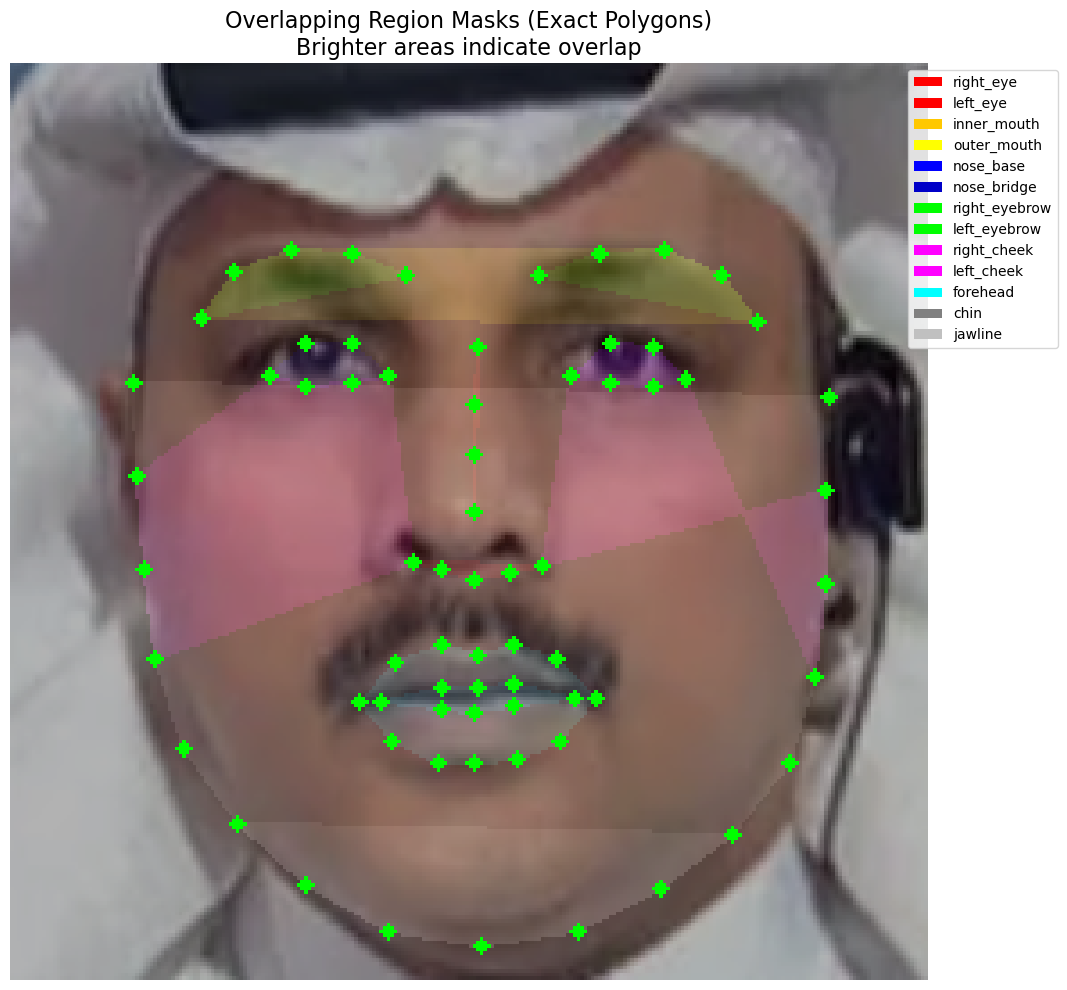

In [9]:
def visualize_overlapping_masks(image, masks, region_definitions, median_landmarks):
    """Visualize overlapping masks with blending."""
    overlay = image.copy()
    combined_mask = np.zeros_like(image, dtype=np.float32)
    
    # Blend all masks with transparency
    for region_name, mask in masks.items():
        color = np.array(region_definitions[region_name]['color'], dtype=np.float32)
        colored_mask = np.zeros_like(image, dtype=np.float32)
        colored_mask[mask > 0] = color
        combined_mask += colored_mask * 0.3  # Lower alpha to show overlaps
    
    # Clip values
    combined_mask = np.clip(combined_mask, 0, 255).astype(np.uint8)
    
    result = cv2.addWeighted(overlay, 0.7, combined_mask, 0.3, 0)
    
    # Draw median landmarks
    for x, y in median_landmarks:
        cv2.circle(result, (x, y), 2, (0, 255, 0), -1)
    
    return result

# Visualize
first_frame_vis = visualize_overlapping_masks(first_frame, region_masks, 
                                              REGION_DEFINITIONS, median_landmarks)

plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(first_frame_vis, cv2.COLOR_BGR2RGB))
plt.title('Overlapping Region Masks (Exact Polygons)\nBrighter areas indicate overlap', fontsize=16)
plt.axis('off')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=np.array(info['color'])/255, label=name) 
    for name, info in REGION_DEFINITIONS.items()
]
plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))

plt.tight_layout()
plt.show()

## Visualize Overlap Map

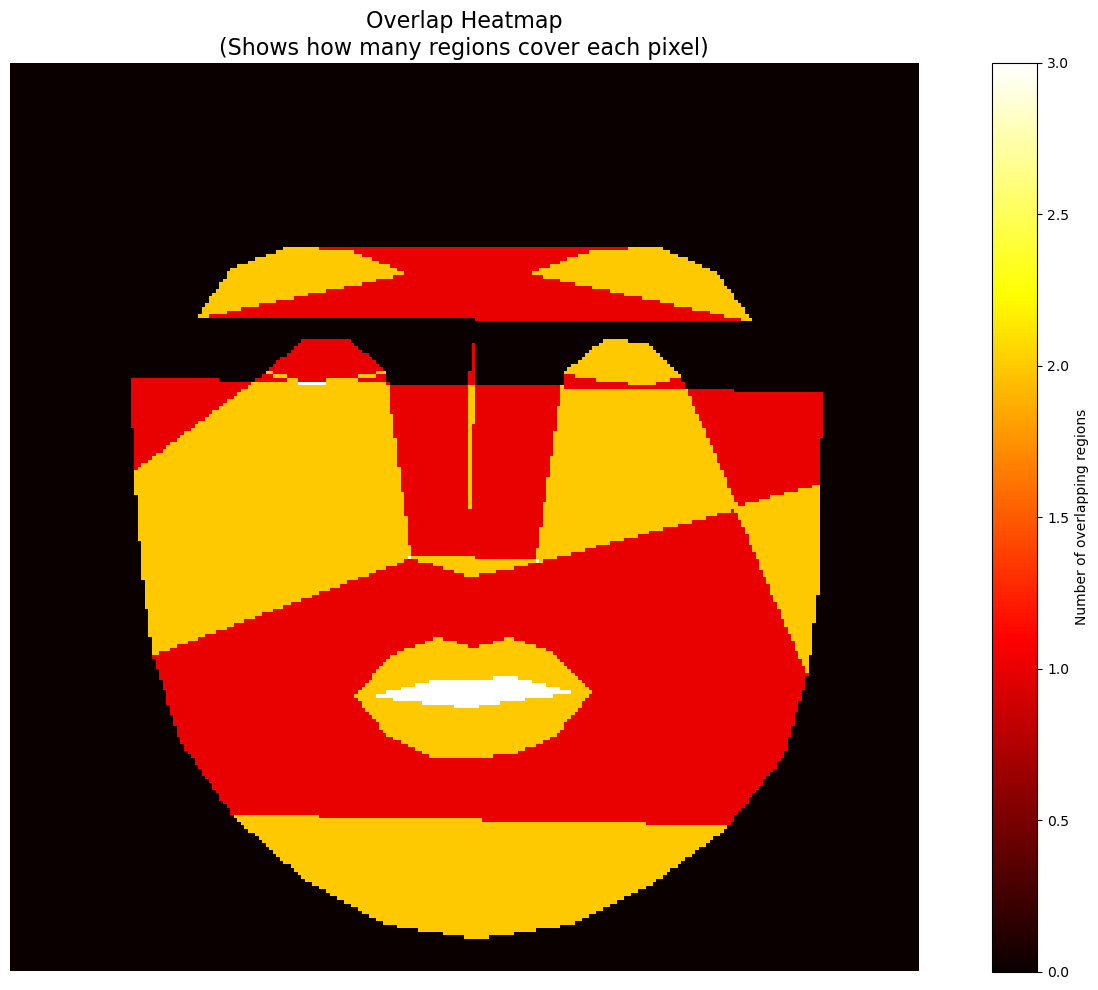


=== Overlap Distribution ===
1 region(s):   15629 pixels (23.85%)
2 region(s):   13047 pixels (19.91%)
3 region(s):     296 pixels (0.45%)


In [10]:
# Create overlap heatmap
overlap_count = np.zeros(image_shape[:2], dtype=np.uint8)

for mask in region_masks.values():
    overlap_count += (mask > 0).astype(np.uint8)

# Visualize overlap heatmap
plt.figure(figsize=(15, 10))
plt.imshow(overlap_count, cmap='hot', interpolation='nearest')
plt.colorbar(label='Number of overlapping regions')
plt.title('Overlap Heatmap\n(Shows how many regions cover each pixel)', fontsize=16)
plt.axis('off')
plt.tight_layout()
plt.show()

# Statistics
unique, counts = np.unique(overlap_count, return_counts=True)
print("\n=== Overlap Distribution ===")
for num_regions, pixel_count in zip(unique, counts):
    if num_regions > 0:
        print(f"{num_regions} region(s): {pixel_count:>7} pixels ({pixel_count/np.sum(counts)*100:.2f}%)")

## Individual Region Visualization

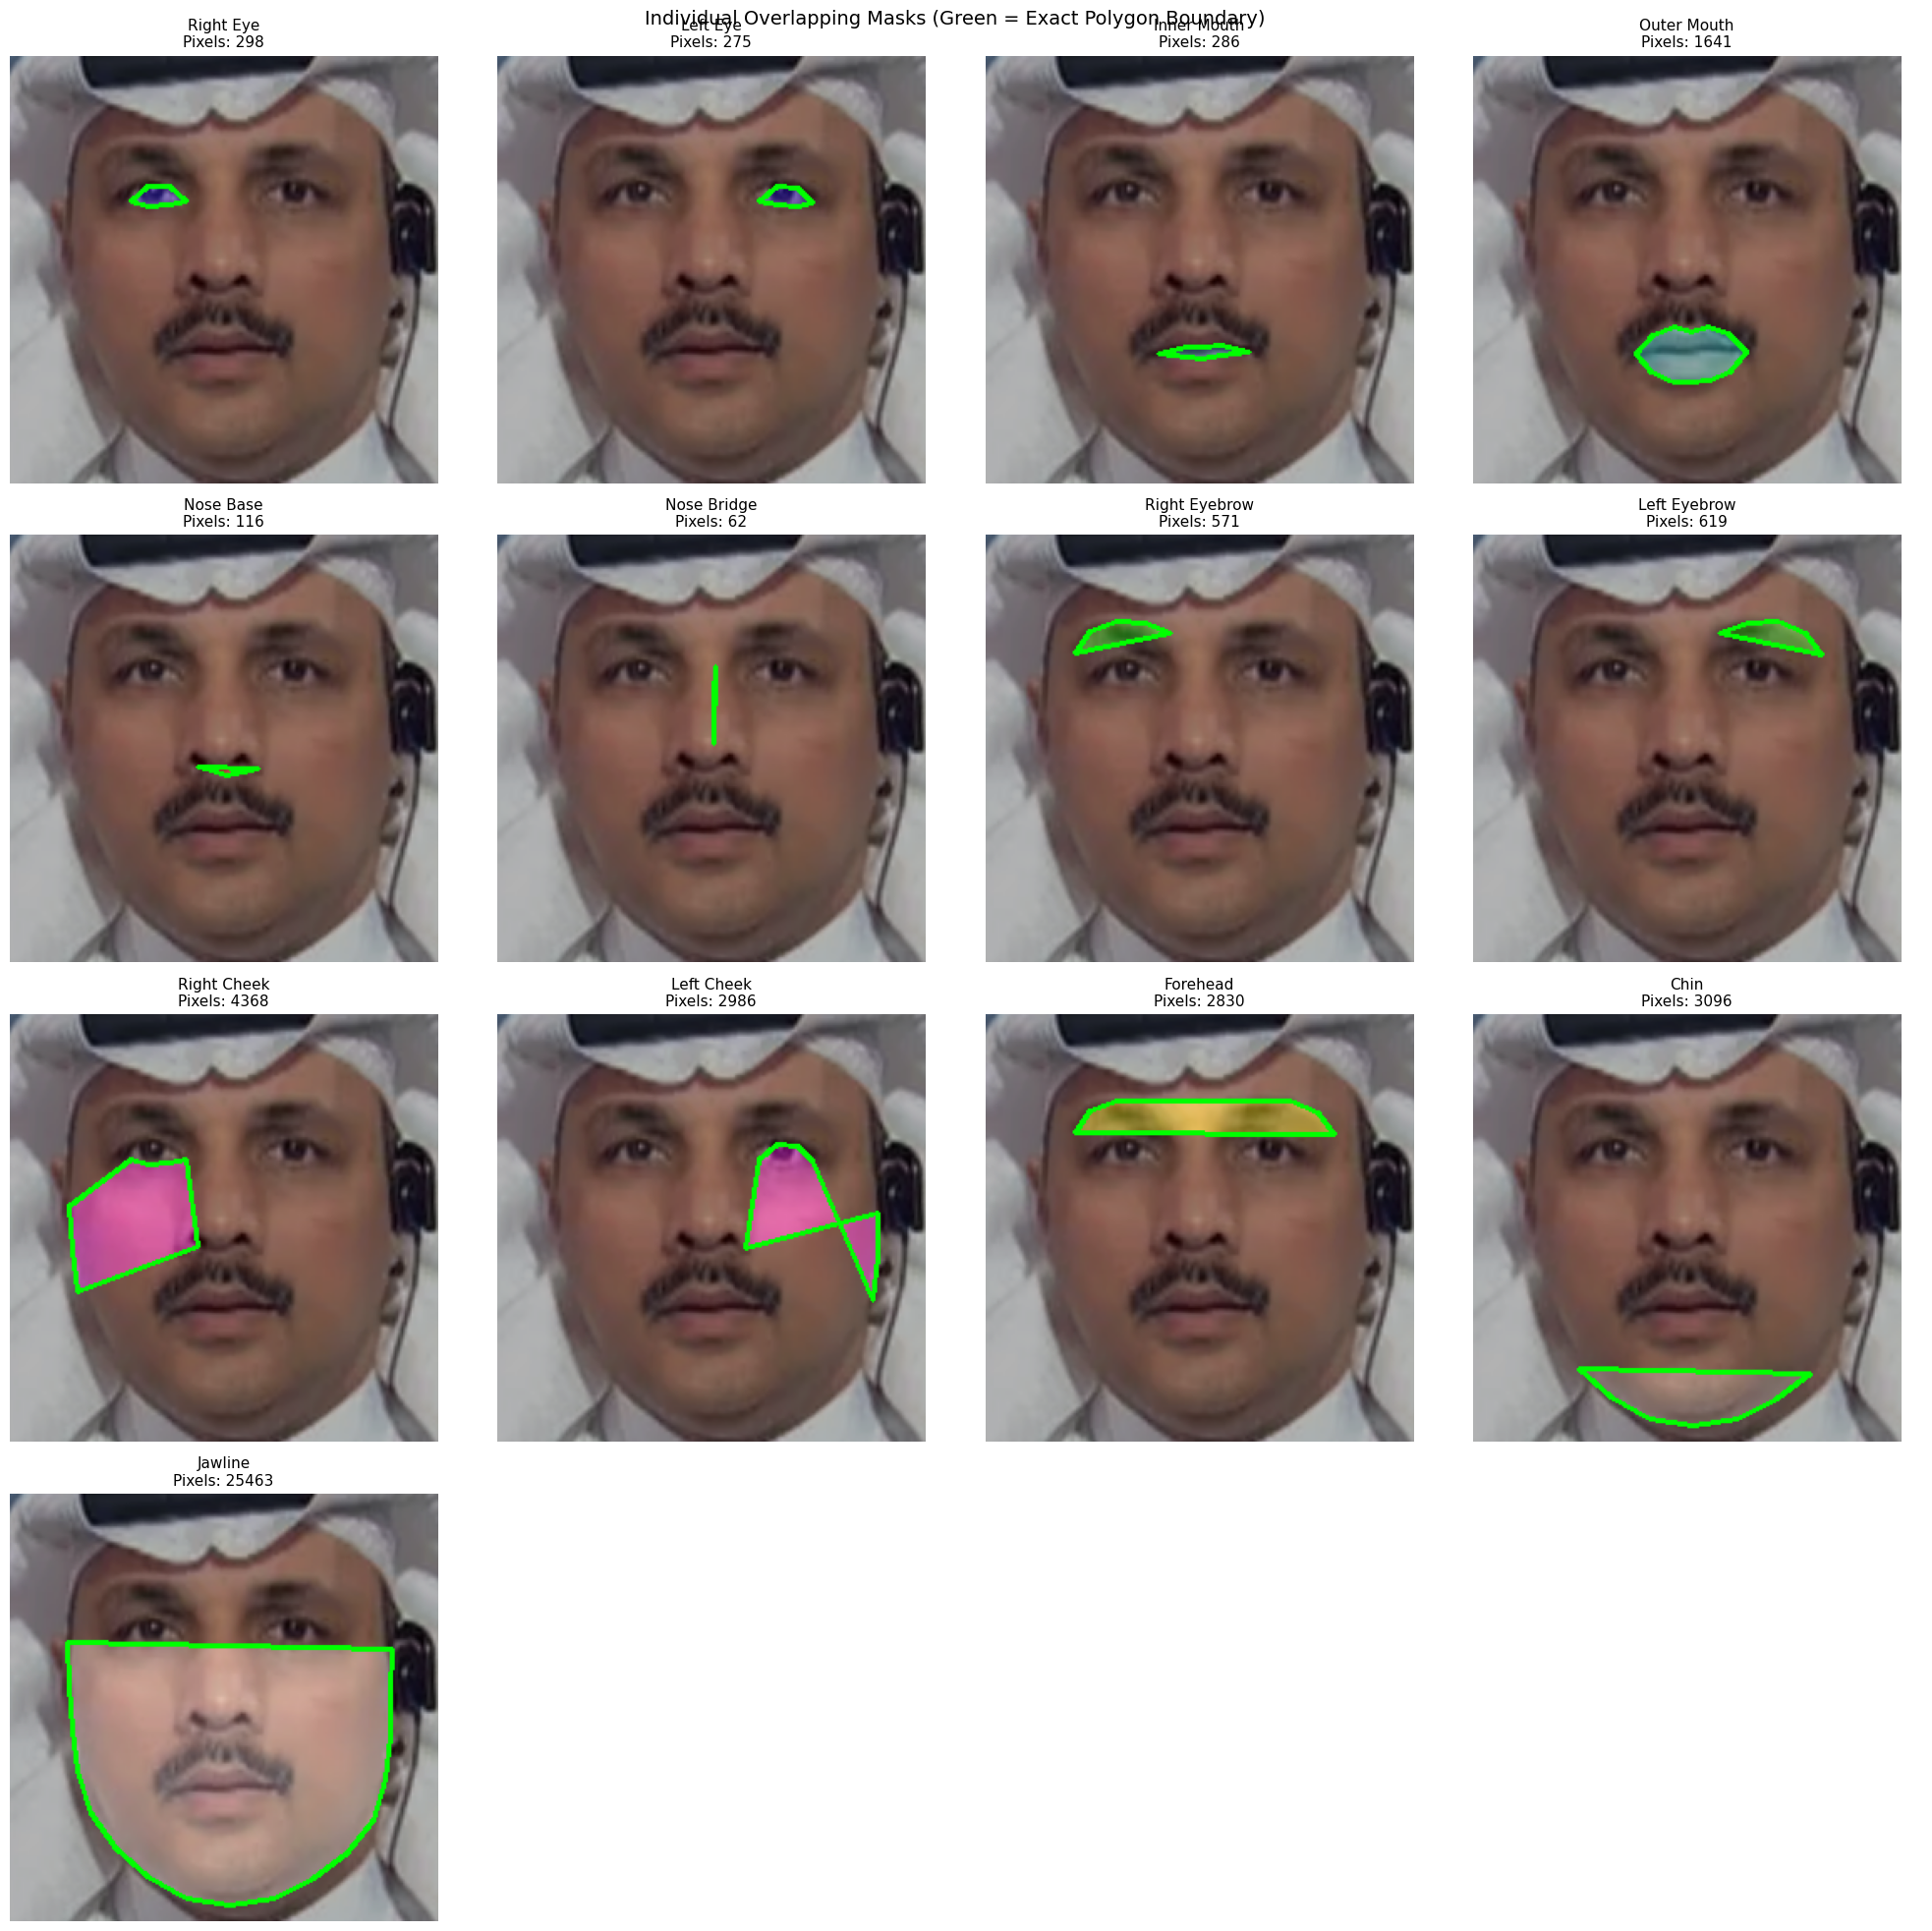

In [12]:
n_regions = len(region_masks)
n_cols = 4
n_rows = (n_regions + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
axes = axes.flatten()

for idx, (region_name, mask) in enumerate(region_masks.items()):
    ax = axes[idx]
    
    vis_image = first_frame.copy()
    colored_mask = np.zeros_like(vis_image)
    color = REGION_DEFINITIONS[region_name]['color']
    colored_mask[mask > 0] = color
    result = cv2.addWeighted(vis_image, 0.7, colored_mask, 0.3, 0)
    
    # Draw polygon boundary
    indices = REGION_DEFINITIONS[region_name]['indices']
    points = median_landmarks[indices].astype(np.int32)
    cv2.polylines(result, [points], True, (0, 255, 0), 2)
    
    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    pixel_count = np.sum(mask > 0)
    ax.set_title(f'{region_name.replace("_", " ").title()}\nPixels: {pixel_count}', fontsize=11)
    ax.axis('off')

for idx in range(n_regions, len(axes)):
    axes[idx].axis('off')

plt.suptitle('Individual Overlapping Masks (Green = Exact Polygon Boundary)', fontsize=14)
plt.tight_layout()
plt.show()

## Test Stability Across Frames

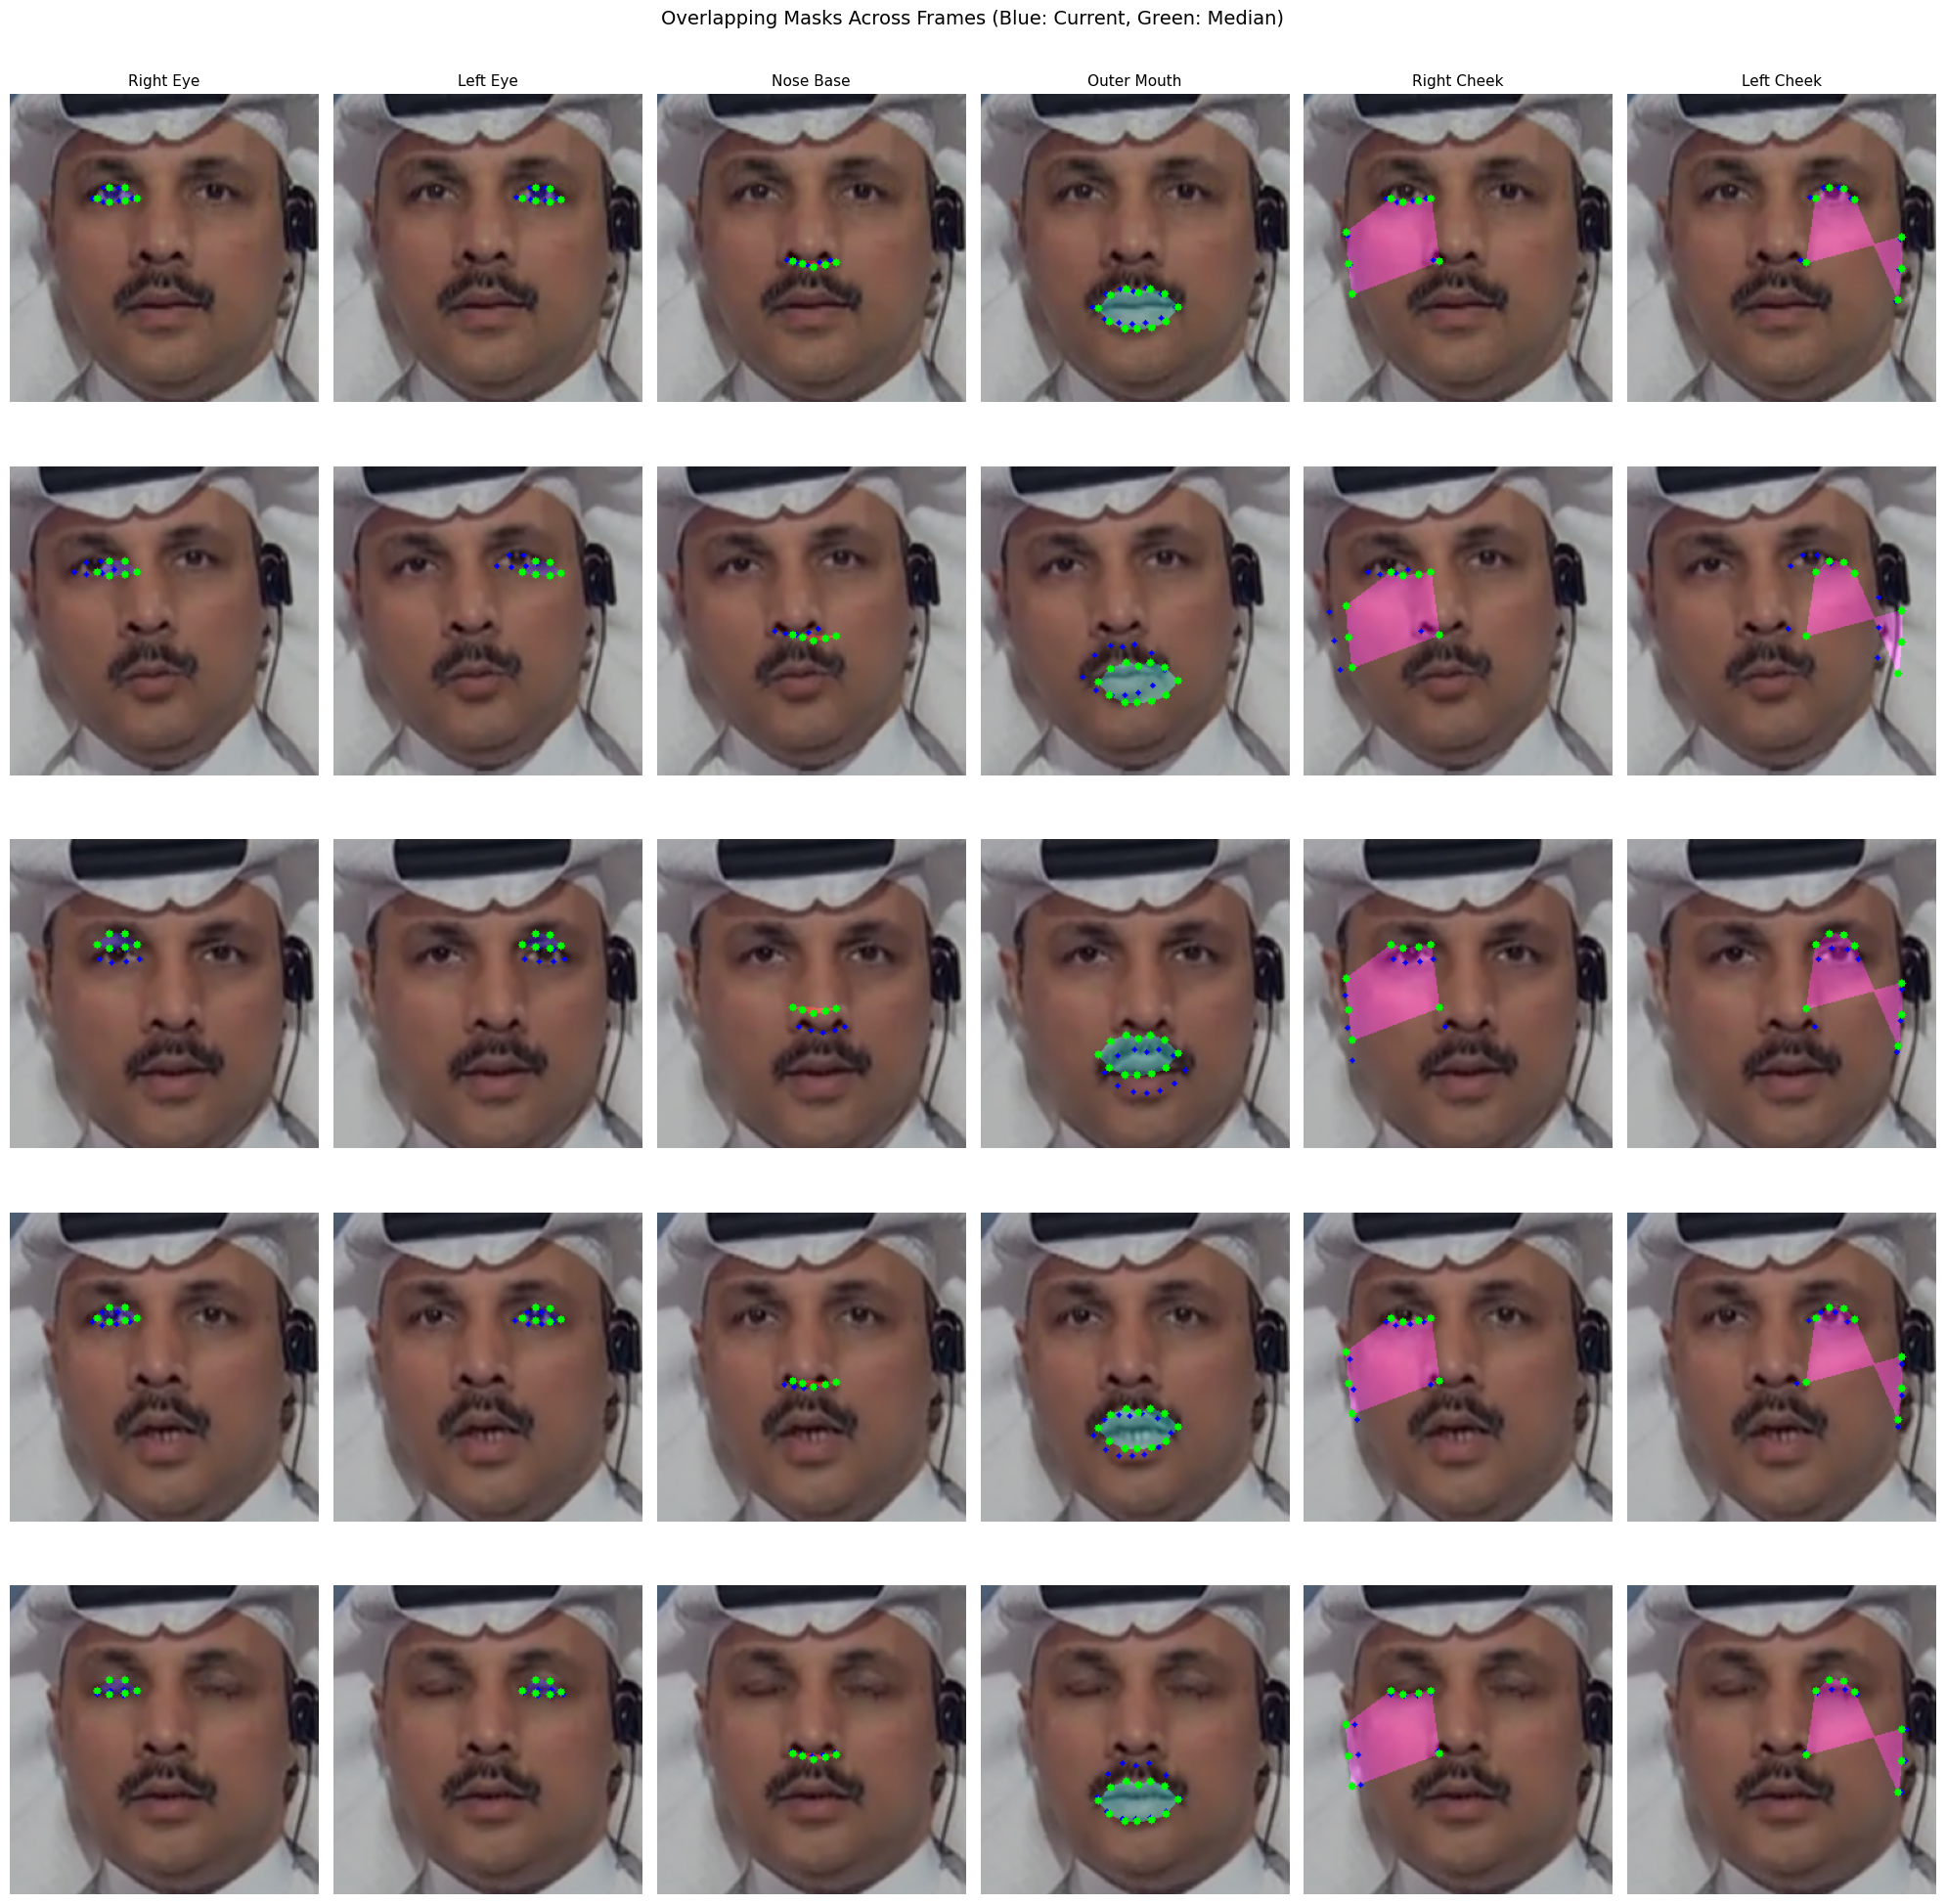

In [13]:
n_frames = len(valid_images)
test_frame_indices = [0, n_frames//4, n_frames//2, 3*n_frames//4, n_frames-1]

key_regions = ['right_eye', 'left_eye', 'nose_base', 'outer_mouth', 'right_cheek', 'left_cheek']

fig, axes = plt.subplots(len(test_frame_indices), len(key_regions), 
                         figsize=(20, 4*len(test_frame_indices)))

for row_idx, frame_idx in enumerate(test_frame_indices):
    frame = cv2.imread(str(valid_images[frame_idx]))
    current_landmarks = all_landmarks[frame_idx]
    
    for col_idx, region_name in enumerate(key_regions):
        ax = axes[row_idx, col_idx]
        
        vis_image = frame.copy()
        mask = region_masks[region_name]
        colored_mask = np.zeros_like(vis_image)
        color = REGION_DEFINITIONS[region_name]['color']
        colored_mask[mask > 0] = color
        result = cv2.addWeighted(vis_image, 0.7, colored_mask, 0.3, 0)
        
        # Draw current frame landmarks (blue)
        indices = REGION_DEFINITIONS[region_name]['indices']
        for idx in indices:
            x, y = current_landmarks[idx]
            cv2.circle(result, (int(x), int(y)), 2, (255, 0, 0), -1)
        
        # Draw median landmarks (green)
        for idx in indices:
            x, y = median_landmarks[idx]
            cv2.circle(result, (int(x), int(y)), 3, (0, 255, 0), -1)
        
        ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
        
        if row_idx == 0:
            ax.set_title(region_name.replace('_', ' ').title(), fontsize=11)
        if col_idx == 0:
            ax.set_ylabel(f'Frame {frame_idx}', fontsize=11)
        ax.axis('off')

plt.suptitle('Overlapping Masks Across Frames (Blue: Current, Green: Median)', 
             fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

## Coverage Statistics

In [14]:
def calculate_mask_coverage(landmarks, mask, region_indices):
    """Calculate percentage of landmarks within mask."""
    points = landmarks[region_indices]
    inside_count = 0
    
    for x, y in points:
        if 0 <= int(y) < mask.shape[0] and 0 <= int(x) < mask.shape[1]:
            if mask[int(y), int(x)] > 0:
                inside_count += 1
    
    return inside_count / len(points) * 100

coverage_stats = defaultdict(list)

for frame_idx, landmarks in enumerate(all_landmarks):
    for region_name, mask in region_masks.items():
        indices = REGION_DEFINITIONS[region_name]['indices']
        coverage = calculate_mask_coverage(landmarks, mask, indices)
        coverage_stats[region_name].append(coverage)

print("\n=== Overlapping Mask Coverage ===")
print(f"{'Region':<20} {'Mean':<10} {'Min':<10} {'Max':<10} {'Std':<10}")
print("-" * 60)

for region_name in sorted(coverage_stats.keys()):
    coverages = coverage_stats[region_name]
    print(f"{region_name:<20} {np.mean(coverages):>6.2f}%   "
          f"{np.min(coverages):>6.2f}%   {np.max(coverages):>6.2f}%   "
          f"{np.std(coverages):>6.2f}%")


=== Overlapping Mask Coverage ===
Region               Mean       Min        Max        Std       
------------------------------------------------------------
chin                  37.39%     0.00%    85.71%    30.99%
forehead              43.75%     0.00%   100.00%    26.35%
inner_mouth           39.16%     0.00%    87.50%    22.88%
jawline               47.43%     0.00%    88.24%    20.24%
left_cheek            37.70%     0.00%    75.00%    15.39%
left_eye              37.37%     0.00%    83.33%    18.25%
left_eyebrow          39.53%     0.00%    80.00%    22.29%
nose_base             29.69%     0.00%   100.00%    25.49%
nose_bridge           10.55%     0.00%   100.00%    26.26%
outer_mouth           46.74%     0.00%   100.00%    23.74%
right_cheek           42.77%     0.00%    87.50%    25.75%
right_eye             41.80%     0.00%   100.00%    19.54%
right_eyebrow         36.25%     0.00%   100.00%    29.13%


## Save Masks

In [ ]:
output_data = {
    'video_id': VIDEO_ID,
    'median_landmarks': median_landmarks,
    'region_masks': region_masks,
    'region_definitions': REGION_DEFINITIONS,
    'image_shape': image_shape,
    'coverage_stats': dict(coverage_stats),
    'overlap_matrix': overlap_matrix,
    'overlapping': True
}

output_path = f'/mnt/user-data/outputs/overlapping_masks_{VIDEO_ID}.pkl'
with open(output_path, 'wb') as f:
    pickle.dump(output_data, f)

print(f"\nSaved to: {output_path}")

# Save individual masks
for region_name, mask in region_masks.items():
    cv2.imwrite(f'/mnt/user-data/outputs/overlap_mask_{region_name}.png', mask)

print(f"Saved {len(region_masks)} individual masks")

## Summary

**Overlapping Masks Features:**
- ✅ Natural overlaps between adjacent regions
- ✅ Exact polygon boundaries (no smoothing)
- ✅ Independent region definitions
- ✅ Overlap heatmap showing transitional zones
- ✅ Stable in image space

**Use Cases:**
- Analyzing transitional zones between regions
- Multi-region feature extraction
- Studying region interactions
- More flexible region coverage

**Comparison with Non-Overlapping:**
- Overlapping: More coverage, natural boundaries, regions can share pixels
- Non-Overlapping: Mutually exclusive, clear partitioning, no ambiguity